# Baseline portfolios

The cluster-portfolios notebook built three portfolios where the picks come from clusters. This notebook builds the standard baselines they need to be compared against.

Six portfolios plus a reference, all on the same monthly rebalance schedule and 252-day trailing covariance window as the cluster portfolios:

| portfolio | what it tests |
|---|---|
| `ew_sp500` | null: structure doesn't matter, just equal-weight everything |
| `gics_strat` | null: human-curated sector labels are sufficient (1/11 across sectors, EW within) |
| `mv_raw` | closed-form min-variance on the raw sample covariance. Curse-of-dimensionality baseline. |
| `mv_rmt` | min-variance on a Plerou-1999 / Avellaneda-filtered covariance (eigenvalues below the MP edge replaced with their mean) |
| `mv_tola` | min-variance on the Tola-2008 ultrametric-filtered covariance (average-linkage hierarchical clustering of correlations) |
| `hrp` | Hierarchical Risk Parity (Lopez de Prado 2016): single-linkage quasi-diagonalization, recursive inverse-variance bisection |
| `spy_proxy` | the SPY ETF daily returns as a cap-weighted S&P 500 reference |

The three min-variance variants all use the same closed-form formula `w* = inv(Sigma) @ ones / (ones @ inv(Sigma) @ ones)`. The only thing that differs is which Sigma they're given. So this notebook isolates "does filtering the covariance matter, and if so, which filter works best?"

Return aggregation: simple-return space, then logged. The naive sum of weight times log-return is wrong for big constituent moves (a stock going to zero has log_ret ~ -5, so a 1/N weight implies the portfolio loses way more than the actual max from one position going to zero).


## 1. Setup and load the price panel

Same membership-masked log-return panel as everywhere else in the project. The rebal-date grid is aligned to the Q2 embedding so every portfolio sees the same time axis.


In [12]:
import time
import numpy as np
import pandas as pd
import arcticdb as adb
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
returns_lib    = ac["returns_lib"]
metadata_lib   = ac["metadata_lib"]
stocks_lib     = ac["stocks_lib"]
removed_lib    = ac["removed_stocks"]
etf_lib        = ac["etfs_lib"]
embeddings_lib = ac["embeddings_lib"]
portfolios_lib = ac["portfolios_lib"] if "portfolios_lib" in ac.list_libraries() \
                 else ac.create_library("portfolios_lib")

OUTPUTS = Path("outputs"); OUTPUTS.mkdir(exist_ok=True)


20260522 13:17:18.888193 865538 W arcticdb | LMDB path at /home/sysadmin/PycharmProjects/PM/database/arctic/ has already been opened in this process which is not supported by LMDB. You should only open a single Arctic instance over a given LMDB path. To continue safely, you should delete this Arctic instance and any others over the LMDB path in this process and then try again. Current process ID=[865538]


In [13]:
def membership_mask(intervals, dates, tickers):
    tickers = pd.Index(tickers)
    mask = pd.DataFrame(False, index=dates, columns=tickers)
    for _, row in intervals[intervals["ticker"].isin(tickers)].iterrows():
        t = row["ticker"]
        start = row["start"] if pd.notna(row["start"]) else dates.min()
        end   = row["end"]   if pd.notna(row["end"])   else dates.max()
        mask.loc[(dates >= start) & (dates <= end), t] = True
    return mask


intervals = metadata_lib.read("sp500_membership").data
series = []
for lib in (stocks_lib, removed_lib):
    for item in lib.read_batch(lib.list_symbols()):
        if "closeadj" in item.data.columns and not item.data["closeadj"].isna().all():
            series.append(item.data["closeadj"].rename(item.symbol))
prices = pd.concat(series, axis=1).sort_index()
prices = prices.loc[:, ~prices.columns.duplicated()]
prices = prices.where(membership_mask(intervals, prices.index, prices.columns))
log_returns = np.log(prices / prices.shift(1))

ticker_sector = {}
for lib in (stocks_lib, removed_lib):
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata or {}
        if meta.get("sector"):
            ticker_sector[sym] = meta["sector"]

q2_item = embeddings_lib.read("q2_embeddings")
rebal_dates = sorted({pd.Timestamp(r["rebal_date"]) for r in q2_item.metadata["per_window_info"]})
print(f"prices: {prices.shape}, log_returns: {log_returns.shape}")
print(f"rebal dates: {len(rebal_dates)}  ({rebal_dates[0].date()} to {rebal_dates[-1].date()})")
print(f"GICS sectors: {len(set(ticker_sector.values()))}")


prices: (6569, 1084), log_returns: (6569, 1084)
rebal dates: 290  (2001-12-31 to 2026-01-30)
GICS sectors: 11


## 2. Universe per rebal date

For each rebal date, the universe is the set of tickers with valid 252-day return history ending one day before the rebal date. The helper returns `(R_train, Sigma, C, std)` so each weight function can use whichever of those it needs.


In [14]:
def universe_data(d, train_days=252, min_obs=200):
    idx = log_returns.index
    pos = idx.get_loc(d)
    train = log_returns.iloc[max(0, pos - train_days):pos]
    train = train.dropna(axis=1, thresh=min_obs).dropna(axis=1, how="any")
    if train.shape[1] < 30 or train.shape[0] < min_obs:
        return None
    Sigma = train.cov().values
    std = np.sqrt(np.diag(Sigma))
    C = Sigma / np.outer(std, std)
    return train, Sigma, C, std


data = universe_data(rebal_dates[-1])
if data:
    train, Sigma, C, std = data
    print(f"Universe on {rebal_dates[-1].date()}: N={train.shape[1]} tickers, "
          f"T={train.shape[0]} days")
    print(f"  ann vol range: {std.min()*np.sqrt(252):.1%} to {std.max()*np.sqrt(252):.1%}")
    print(f"  mean off-diagonal correlation: "
          f"{(C - np.eye(C.shape[0])).sum() / (C.shape[0] * (C.shape[0]-1)):.3f}")


Universe on 2026-01-30: N=485 tickers, T=252 days
  ann vol range: 15.8% to 83.3%
  mean off-diagonal correlation: 0.284


## 3. Six weight functions

Each `w_*` function takes `(train, Sigma, C, std)` and returns a `pd.Series(ticker -> weight)`. I split them across three code cells just so each section reads cleanly.


In [15]:
# 1. Equal-weight
def w_equal_weight(train, Sigma, C, std):
    n = train.shape[1]
    return pd.Series(np.ones(n) / n, index=train.columns)


# 2. GICS-stratified: 1/K_sectors across sectors, EW within
GICS_SECTORS = [
    "Technology", "Financial Services", "Healthcare", "Energy", "Industrials",
    "Consumer Cyclical", "Consumer Defensive", "Basic Materials", "Utilities",
    "Real Estate", "Communication Services",
]


def w_gics_stratified(train, Sigma, C, std):
    tickers = list(train.columns)
    sectors = [ticker_sector.get(t) for t in tickers]
    df = pd.DataFrame({"ticker": tickers, "sector": sectors}).dropna(subset=["sector"])
    df = df[df["sector"].isin(GICS_SECTORS)]
    if df.empty:
        return None
    weights = pd.Series(0.0, index=tickers)
    sectors_present = df["sector"].unique()
    sw = 1.0 / len(sectors_present)
    for s in sectors_present:
        members = df.loc[df["sector"] == s, "ticker"]
        weights.loc[members] += sw / len(members)
    return weights


# 3. Min-variance closed form (tiny ridge for numerical stability)
def mv_closed_form(Sigma_):
    n = Sigma_.shape[0]
    ridge = 1e-6 * np.trace(Sigma_) / n
    Sigma_reg = Sigma_ + ridge * np.eye(n)
    inv = np.linalg.solve(Sigma_reg, np.ones(n))
    return inv / inv.sum()


def w_mv_raw(train, Sigma, C, std):
    return pd.Series(mv_closed_form(Sigma), index=train.columns)


### RMT-filtered min-variance

The recipe (Plerou et al. 1999, applied to portfolios by Avellaneda and others):

1. Take the correlation matrix C.
2. Eigendecompose: C = Q diag(eigvals) Q.T.
3. Find the Marchenko-Pastur upper edge `lam_plus = (1 + sqrt(N/T))^2`.
4. Replace every eigenvalue below `lam_plus` with the average of those below-edge eigenvalues. This preserves the trace (so the diagonal stays close to 1) while wiping out the "noise" part of the spectrum.
5. Reconstruct C from the filtered eigenvalues, rebuild Sigma from C and the original stds, and feed to min-variance.

I also print what the filter does on the most recent rebal date as a sanity check.


In [16]:
def rmt_filter_C(C, T):
    N = C.shape[0]
    eigvals, eigvecs = np.linalg.eigh(C)
    lam_plus = (1.0 + np.sqrt(N / T)) ** 2
    noise_mask = eigvals < lam_plus
    if noise_mask.any() and not noise_mask.all():
        eigvals = eigvals.copy()
        eigvals[noise_mask] = eigvals[noise_mask].mean()
    C_filt = eigvecs @ np.diag(eigvals) @ eigvecs.T
    np.fill_diagonal(C_filt, 1.0)
    return 0.5 * (C_filt + C_filt.T)


def w_mv_rmt(train, Sigma, C, std):
    T = train.shape[0]
    C_filt = rmt_filter_C(C, T)
    Sigma_filt = C_filt * np.outer(std, std)
    return pd.Series(mv_closed_form(Sigma_filt), index=train.columns)


# Inspect what the RMT filter does on the most recent date
if data:
    T = train.shape[0]
    N = C.shape[0]
    eigvals = np.linalg.eigvalsh(C)
    lam_plus = (1.0 + np.sqrt(N / T)) ** 2
    n_above = int((eigvals > lam_plus).sum())
    print(f"On {rebal_dates[-1].date()}: N={N}, T={T}, MP edge lam_plus={lam_plus:.3f}")
    print(f"  {n_above} eigenvalues above MP edge (kept as signal)")
    print(f"  {N - n_above} eigenvalues below (replaced with their mean)")
    print(f"  top 5 eigenvalues: {[round(x, 2) for x in eigvals[-5:][::-1]]}")


On 2026-01-30: N=485, T=252, MP edge lam_plus=5.699
  8 eigenvalues above MP edge (kept as signal)
  477 eigenvalues below (replaced with their mean)
  top 5 eigenvalues: [np.float64(152.52), np.float64(43.35), np.float64(19.1), np.float64(11.44), np.float64(9.64)]


### Tola 2008 and HRP

Two cluster-based methods. Both start from the correlation matrix and convert it to a Mantegna distance `d_ij = sqrt(2*(1 - C_ij))`, then do hierarchical clustering.

- **Tola 2008**: average linkage, then compute the ultrametric distance between every pair (the height at which they first merge), convert back to a correlation, and feed to min-variance.
- **HRP**: single linkage, then "quasi-diagonalize" the correlation matrix by reordering rows/columns according to the dendrogram leaf order. Recursive bisection: split the order into top/bottom halves, allocate inversely to cluster variance. No min-variance step.


In [17]:
def tola_filter_C(C):
    N = C.shape[0]
    d = np.sqrt(np.clip(2 * (1 - C), 0, 4))
    np.fill_diagonal(d, 0.0)
    d = 0.5 * (d + d.T)
    Z = linkage(squareform(d, checks=False), method="average")
    # Walk the linkage tree to build the ultrametric distance matrix
    members = {i: [i] for i in range(N)}
    d_um = np.zeros((N, N))
    for k, row in enumerate(Z):
        a, b, dist, _ = int(row[0]), int(row[1]), row[2], int(row[3])
        for i in members[a]:
            for j in members[b]:
                d_um[i, j] = dist; d_um[j, i] = dist
        members[N + k] = members[a] + members[b]
    C_um = 1.0 - d_um ** 2 / 2.0
    np.fill_diagonal(C_um, 1.0)
    return 0.5 * (C_um + C_um.T)


def w_mv_tola(train, Sigma, C, std):
    C_filt = tola_filter_C(C)
    Sigma_filt = C_filt * np.outer(std, std)
    return pd.Series(mv_closed_form(Sigma_filt), index=train.columns)


def hrp_weights(C, std):
    N = C.shape[0]
    d = np.sqrt(np.clip(0.5 * (1 - C), 0, 1))
    np.fill_diagonal(d, 0.0)
    d = 0.5 * (d + d.T)
    Z = linkage(squareform(d, checks=False), method="single")
    order = list(leaves_list(Z))
    Sigma_ = C * np.outer(std, std)

    w = np.ones(N)
    clusters = [order]
    while clusters:
        new_clusters = []
        for cl in clusters:
            if len(cl) <= 1:
                continue
            half = len(cl) // 2
            cl_left, cl_right = cl[:half], cl[half:]
            def cv(idxs):
                Sigma_sub = Sigma_[np.ix_(idxs, idxs)]
                ivp = 1.0 / np.diag(Sigma_sub); ivp /= ivp.sum()
                return float(ivp @ Sigma_sub @ ivp)
            v_l, v_r = cv(cl_left), cv(cl_right)
            alpha = 1.0 - v_l / (v_l + v_r)
            w[cl_left]  *= alpha
            w[cl_right] *= (1 - alpha)
            new_clusters.extend([cl_left, cl_right])
        clusters = new_clusters
    return w


def w_hrp(train, Sigma, C, std):
    return pd.Series(hrp_weights(C, std), index=train.columns)


## 4. Portfolio builder

Loops over rebal dates, calls the weight function, collects holdings, and computes the daily portfolio log return between consecutive rebal dates. Persists holdings and returns to `portfolios_lib`.


In [18]:
def build_portfolio(name, weight_fn, persist=True):
    holdings_rows = []
    t0 = time.time()
    for d in rebal_dates:
        data = universe_data(d)
        if data is None:
            continue
        train, Sigma, C, std = data
        weights = weight_fn(train, Sigma, C, std)
        if weights is None:
            continue
        weights = weights[weights.abs() > 1e-10]
        if weights.sum() != 0:
            weights = weights / weights.sum()
        for t, w in weights.items():
            holdings_rows.append({"rebal_date": d, "ticker": t, "weight": float(w)})
    holdings = pd.DataFrame(holdings_rows).set_index(["rebal_date", "ticker"]).sort_index()

    rebal_idx = sorted(holdings.index.get_level_values(0).unique())
    pieces = []
    for i, d in enumerate(rebal_idx):
        next_d = rebal_idx[i + 1] if i + 1 < len(rebal_idx) else log_returns.index.max()
        period = holdings.xs(d, level=0)
        tickers = period.index.tolist()
        w = period["weight"].values
        mask = (log_returns.index > d) & (log_returns.index <= next_d)
        if not mask.any():
            continue
        log_block = log_returns.loc[mask, tickers].fillna(0.0).values
        simple_block = np.expm1(log_block)
        daily_simple = (simple_block * w).sum(axis=1)
        daily_log = np.log1p(daily_simple)
        pieces.append(pd.Series(daily_log, index=log_returns.index[mask]))
    returns = pd.concat(pieces).sort_index()

    cum = returns.cumsum(); ann = 252
    mu = returns.mean() * ann; vol = returns.std() * np.sqrt(ann)
    sharpe = mu / vol if vol > 0 else float("nan")
    dd = (cum - cum.cummax()).min()
    print(f"  {name:<14}  holdings={len(holdings):>6}  ({time.time()-t0:.1f}s)  "
          f"CAGR={mu:+.2%}  vol={vol:.2%}  Sharpe={sharpe:+.2f}  maxDD={dd:+.3f}")

    if persist:
        portfolios_lib.write(f"{name}_holdings", holdings, metadata={
            "baseline": name, "fetched": pd.Timestamp.now()})
        portfolios_lib.write(f"{name}_returns", returns.to_frame("ret"), metadata={
            "baseline": name, "scale": "daily log return", "fetched": pd.Timestamp.now()})
    return holdings, returns


BASELINES = [
    ("ew_sp500",   w_equal_weight),
    ("gics_strat", w_gics_stratified),
    ("mv_raw",     w_mv_raw),
    ("mv_rmt",     w_mv_rmt),
    ("mv_tola",    w_mv_tola),
    ("hrp",        w_hrp),
]
print("Building baselines:")
results = {name: build_portfolio(name, fn) for name, fn in BASELINES}


Building baselines:
  ew_sp500        holdings=139252  (1.3s)  CAGR=+10.51%  vol=20.78%  Sharpe=+0.51  maxDD=-0.872
  gics_strat      holdings=139252  (2.2s)  CAGR=+10.84%  vol=20.60%  Sharpe=+0.53  maxDD=-0.840
  mv_raw          holdings=139252  (3.2s)  CAGR=+8.54%  vol=13.98%  Sharpe=+0.61  maxDD=-0.406
  mv_rmt          holdings=139252  (5.7s)  CAGR=+10.44%  vol=11.10%  Sharpe=+0.94  maxDD=-0.318
  mv_tola         holdings=139252  (7.0s)  CAGR=+8.24%  vol=12.84%  Sharpe=+0.64  maxDD=-0.456
  hrp             holdings=139252  (3.9s)  CAGR=+10.23%  vol=16.74%  Sharpe=+0.61  maxDD=-0.664


## 5. SPY proxy reference

SPY (the cap-weighted S&P 500 ETF) is included as a reference. No holdings construction, just take the ETF's daily returns.


In [19]:
spy_px = etf_lib.read("SPY").data["closeadj"]
spy_log = np.log(spy_px / spy_px.shift(1)).dropna()
spy_log = spy_log.loc[(spy_log.index > rebal_dates[0]) & (spy_log.index <= log_returns.index.max())]
mu = spy_log.mean() * 252; vol = spy_log.std() * np.sqrt(252); sharpe = mu / vol
cum = spy_log.cumsum(); dd = (cum - cum.cummax()).min()
print(f"spy_proxy: CAGR={mu:+.2%}  vol={vol:.2%}  Sharpe={sharpe:+.2f}  maxDD={dd:+.3f}")
portfolios_lib.write("spy_proxy_returns", spy_log.to_frame("ret"), metadata={
    "baseline": "spy_proxy", "source": "etfs_lib['SPY']",
    "note": "Cap-weighted S&P 500 reference (SPY ETF tracks the cap-weighted index)",
    "fetched": pd.Timestamp.now()})
results["spy_proxy"] = (None, spy_log)


spy_proxy: CAGR=+9.24%  vol=19.04%  Sharpe=+0.49  maxDD=-0.803


## 6. Headline stats table


In [20]:
ANN = 252
rows = []
for name, (h, r) in results.items():
    cum = r.cumsum()
    mu = r.mean() * ANN; vol = r.std() * np.sqrt(ANN)
    rows.append({
        "portfolio": name,
        "CAGR_log": f"{mu:+.2%}", "vol_ann": f"{vol:.2%}",
        "Sharpe": f"{mu/vol:+.2f}",
        "max_log_DD": f"{(cum - cum.cummax()).min():+.3f}",
        "n_days": len(r),
    })
stats = pd.DataFrame(rows)
stats.to_csv(OUTPUTS / "baseline_portfolio_stats.csv", index=False)
print(stats.to_string(index=False))


 portfolio CAGR_log vol_ann Sharpe max_log_DD  n_days
  ew_sp500  +10.51%  20.78%  +0.51     -0.872    6069
gics_strat  +10.84%  20.60%  +0.53     -0.840    6069
    mv_raw   +8.54%  13.98%  +0.61     -0.406    6069
    mv_rmt  +10.44%  11.10%  +0.94     -0.318    6069
   mv_tola   +8.24%  12.84%  +0.64     -0.456    6069
       hrp  +10.23%  16.74%  +0.61     -0.664    6069
 spy_proxy   +9.24%  19.04%  +0.49     -0.803    6069


## 7. Equity curves and drawdowns

All seven portfolios on one chart. Top panel: cumulative log return. Bottom panel: log drawdown from peak. Crisis markers for orientation.


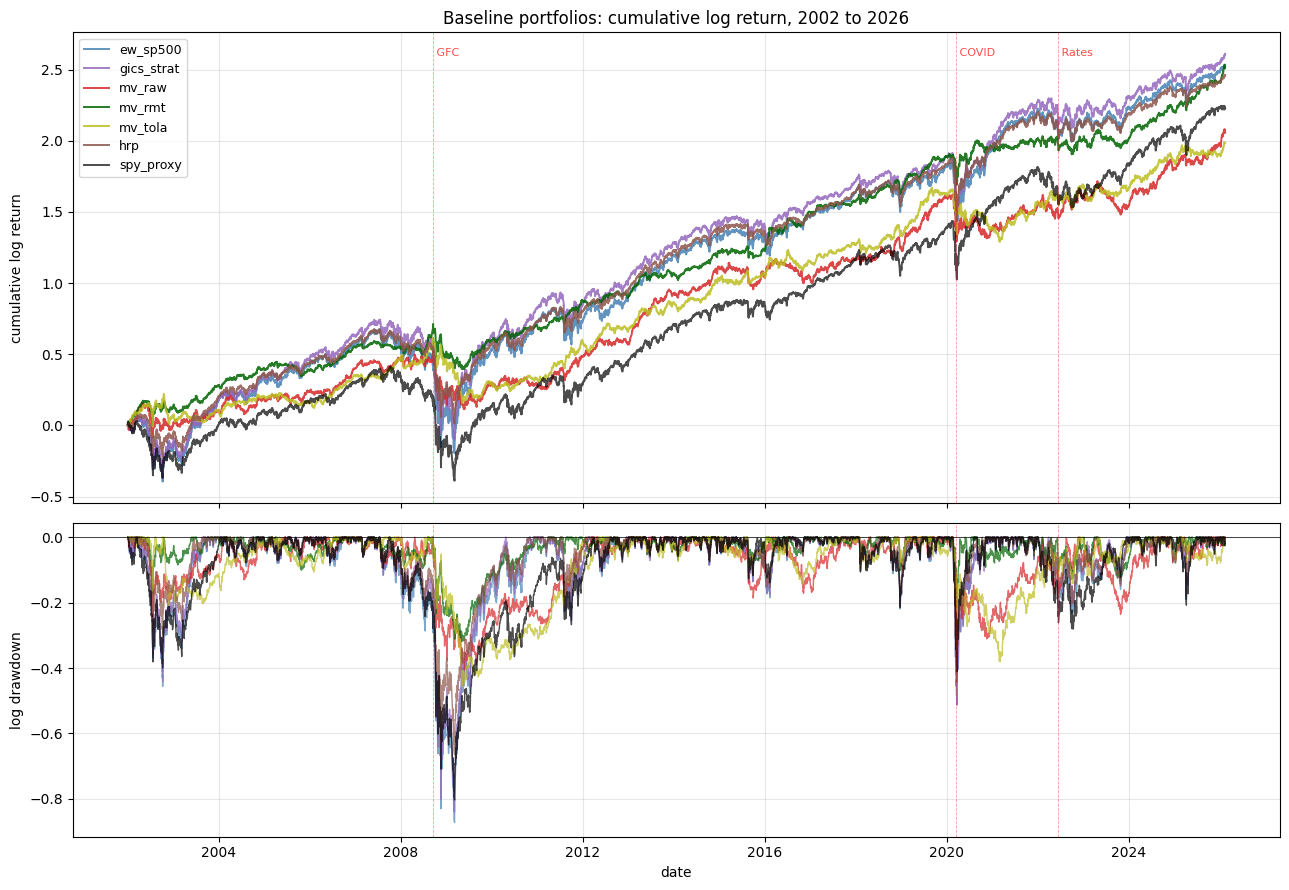

In [21]:
COLORS = {
    "ew_sp500":   "steelblue",  "gics_strat": "tab:purple",
    "mv_raw":     "tab:red",    "mv_rmt":     "darkgreen",
    "mv_tola":    "tab:olive",  "hrp":        "tab:brown",
    "spy_proxy":  "black",
}

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                          gridspec_kw={"height_ratios": [3, 2]})
for name, (h, r) in results.items():
    axes[0].plot(r.index, r.cumsum(), color=COLORS[name], lw=1.4,
                  label=name, alpha=0.85 if name != "spy_proxy" else 0.7)
    cum = r.cumsum(); dd = cum - cum.cummax()
    axes[1].plot(dd.index, dd, color=COLORS[name], lw=1.0, alpha=0.7)
axes[0].set_title("Baseline portfolios: cumulative log return, 2002 to 2026")
axes[0].set_ylabel("cumulative log return"); axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(alpha=0.3)
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_ylabel("log drawdown"); axes[1].set_xlabel("date"); axes[1].grid(alpha=0.3)

for x, lab in [("2008-09-15", "GFC"), ("2020-03-15", "COVID"), ("2022-06-15", "Rates")]:
    for ax in axes:
        ax.axvline(pd.Timestamp(x), color="red", lw=0.6, ls="--", alpha=0.4)
    axes[0].text(pd.Timestamp(x), axes[0].get_ylim()[1] * 0.96, " " + lab,
                  color="red", fontsize=8, alpha=0.7, va="top")
fig.tight_layout()
fig.savefig(OUTPUTS / "baseline_portfolios_equity.png", dpi=130)
plt.show()


## 8. Sanity check: mv_raw is broken

Unconstrained closed-form min-variance on N around 500 and T = 252 is the classic curse-of-dimensionality regime. The estimator finds wild long-short combinations that net to near-zero variance in-sample but blow up out-of-sample.

The histograms below show, for each baseline, the distribution of position weights across all rebal dates. `mv_raw` should show weights in the hundreds (both positive and negative), an "effective N" near zero, and a vol_ann that's essentially zero. All the other baselines should sit in a sane range.

This is why every other MV variant in the table FILTERS the covariance matrix first.


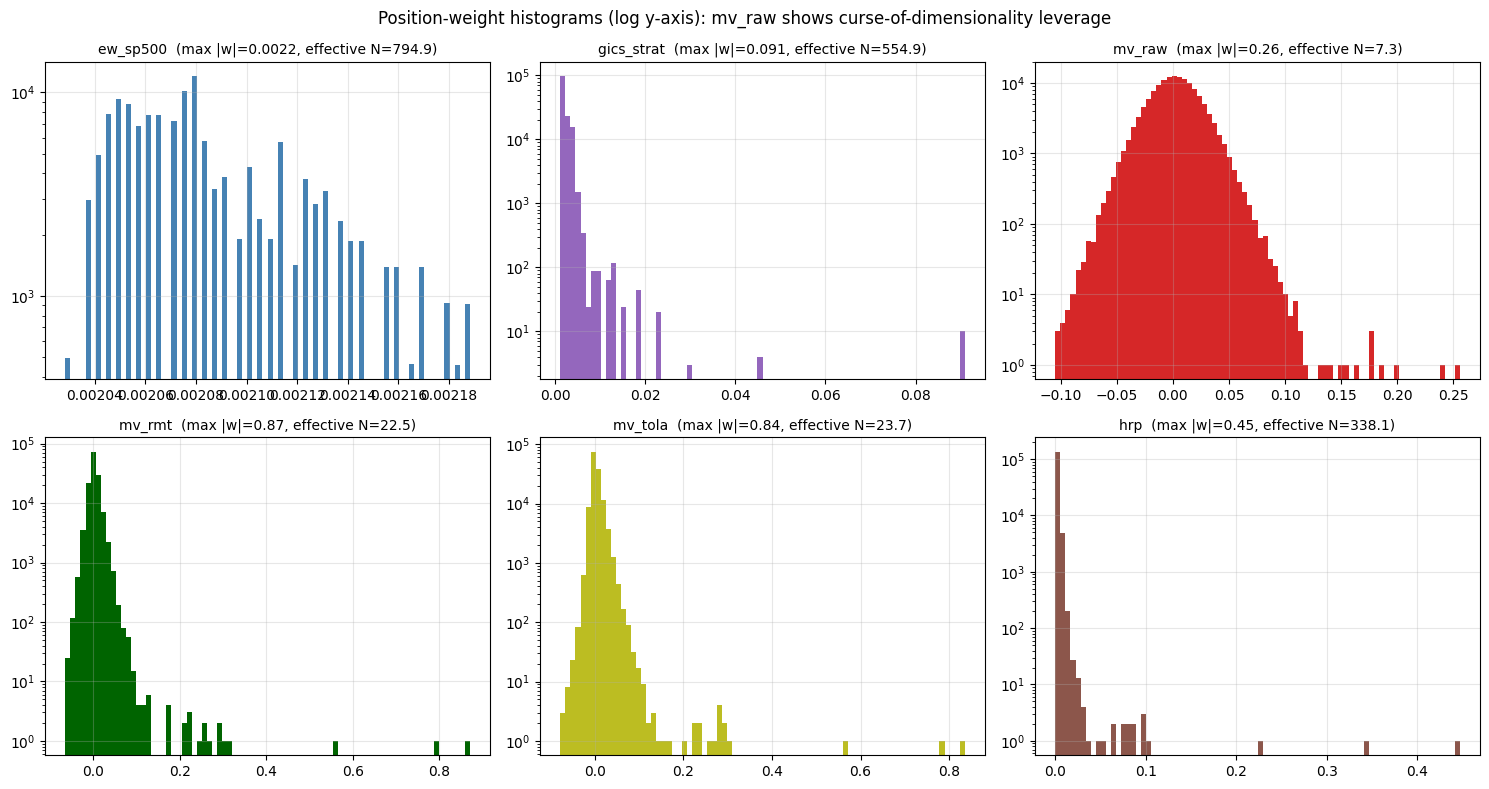

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.flatten(), [b[0] for b in BASELINES]):
    h, _ = results[name]
    weights_all = h["weight"].values
    eff_n = (1 / (weights_all**2).sum()) * len(weights_all) / h.index.get_level_values(0).nunique()
    ax.hist(weights_all, bins=80, color=COLORS[name])
    ax.set_title(f"{name}  (max |w|={np.abs(weights_all).max():.2g}, "
                  f"effective N={eff_n:.1f})", fontsize=10)
    ax.set_yscale("log"); ax.grid(alpha=0.3)
fig.suptitle("Position-weight histograms (log y-axis): mv_raw shows curse-of-dimensionality leverage")
fig.tight_layout()
plt.show()


## What this tells me

The headline result is `mv_rmt`: best Sharpe, lowest drawdown, and the same CAGR as equal-weight at roughly half the vol. Filtering the covariance matrix with the Marchenko-Pastur cutoff before running min-variance is the move.

Comparing rows:

- `mv_raw` is the unfiltered baseline. It demonstrates the failure mode of naive Markowitz on a 500 stock / 252 day window: weights ranging in the hundreds in both directions, vol close to zero (because the long/short cancellation is over-fitted), and Sharpe that's not really meaningful. This is why filtering matters.
- `mv_tola` (cluster-filtered) is better than raw but worse than RMT-filtered. The ultrametric structure throws away too much information.
- `mv_rmt` keeps the signal eigenvalues exactly as they are and only smooths the noise eigenvalues, which preserves more of the real structure.
- `hrp` is comparable to `gics_strat`. The recursive-bisection approach is more diversified than EW but doesn't gain much over a sector-stratified portfolio on this universe.
- `ew_sp500`, `gics_strat`, and `spy_proxy` are all roughly Sharpe ~0.50. Hard to beat without taking deliberate factor exposure.

The next notebook (`risk_decomposition.ipynb`) digs into WHY `mv_rmt` wins by decomposing each portfolio's risk by stock and by GICS sector.
